# Notebook dedicated to construct 3D Plots to illustrate the hit Type distribution

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import glob 
import plotly.graph_objects as go

ModuleNotFoundError: No module named 'plotly'

# Load the Data

In [2]:
fdir = '/home/joankl/data/solars/mc/2p2PPO/electrons/results_npz/resume/resume_npz/'
flist = sorted(glob.glob(fdir + 'e_*MeV_resumed.npz'))

observable_list = ['pmt_db', 'mcid', 'energy_mc', 'pos_mc', 'time_residual_recons', 'hit_type', 'hit_pmt_id', 'dir_mc']

data_dict = {obs_i: [] for obs_i in observable_list}

for file_i in flist:
    np_data = np.load(file_i)

    for obs_i in observable_list:
        data_dict[obs_i].append(np_data[obs_i])

for obs_i in observable_list:
    data_dict[obs_i] = np.concatenate(data_dict[obs_i], axis = 0)

print(data_dict['mcid'].shape)

(14809556,)


## Extract PMT Data Base

The PMT DB is structured as follows: (pmt_id, pos.x, pos.y, pos.z, pmt_type)

In [3]:
pmt_db = data_dict['pmt_db']
pmt_db_id = pmt_db[:,0]
pmt_db_pos_xyz = pmt_db[:,1:4]
pmt_db_type = pmt_db[:,4]

# Data Cuts

1) Apply data cuts
2) Separate hit types

In [4]:
# ========= Data Cuts =========
tres_inf, tres_sup = -4, 20
tres_mask = (data_dict['time_residual_recons'] >= tres_inf) & (data_dict['time_residual_recons'] <= tres_sup)

hit_cher_mask = (data_dict['hit_type'] == 1) # Select Cherenkov Hits 

general_mask = tres_mask & hit_cher_mask

# ========= Select the Data =========

mcid = data_dict['mcid'][general_mask]
energy_mc = data_dict['energy_mc'][general_mask]
pos_mc = data_dict['pos_mc'][general_mask]
hit_pmt_id = data_dict['hit_pmt_id'][general_mask]
dir_mc = data_dict['dir_mc'][general_mask]

hit_pmt_xyz = pmt_db_pos_xyz[hit_pmt_id]

In [5]:
# ========= Separate by events =========
event_start_indices = np.concatenate(([0], np.where(np.diff(mcid) != 0)[0] + 1)) # Array with the indices where an event start (event_start_indices[i]) and ends (event_start_indices[i+1]) 

hit_pmt_xyz_ev = np.split(hit_pmt_xyz, event_start_indices[1:])
energy_ev = energy_mc[event_start_indices]
pos_mc_ev = pos_mc[event_start_indices]
dir_mc_ev = dir_mc[event_start_indices]

# Plots

In [6]:
%matplotlib widget

RuntimeError: 'widget' is not a recognised GUI loop or backend name

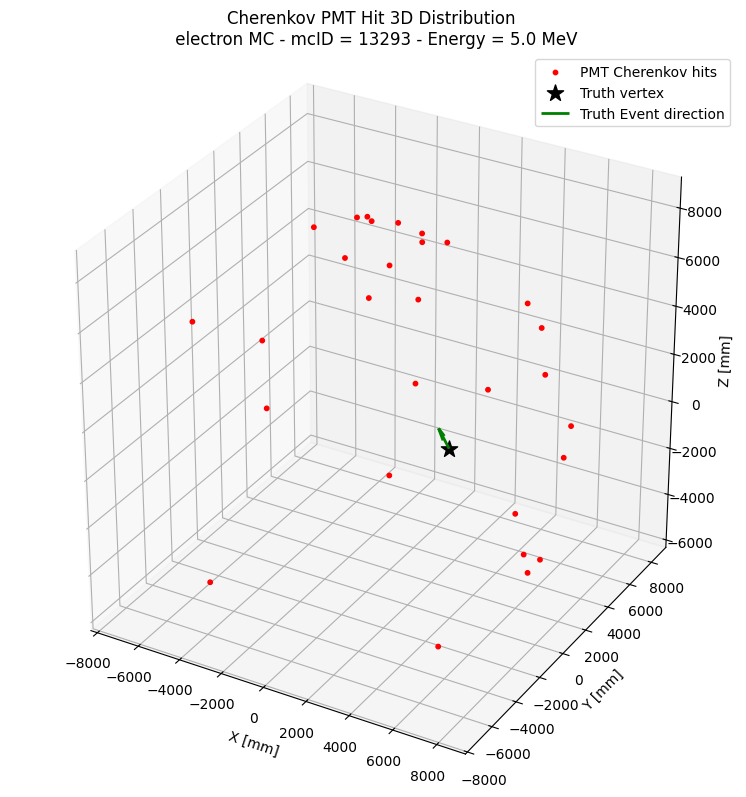

In [7]:
energy_cut = 5.0 # only pick event
energy_mask = energy_ev >= energy_cut

random_evtID = np.random.randint(0, len(energy_ev))  # Random number to pick a random event to plot
#random_evtID = 1018

# ======= Preparing the Data =======
hit_pmt_xyz_ev_i = hit_pmt_xyz_ev[random_evtID]
energy_ev_i = energy_ev[random_evtID]
pos_mc_ev_i = pos_mc_ev[random_evtID]
dir_mc_ev_i = dir_mc_ev[random_evtID]

# Hit coordinates
x = hit_pmt_xyz_ev_i[:, 0]
y = hit_pmt_xyz_ev_i[:, 1]
z = hit_pmt_xyz_ev_i[:, 2]

# Vertex coordinates
vx, vy, vz = pos_mc_ev_i

# Vector Direction
arrow_length = 1000  # representative lenght for visualization
dx, dy, dz = dir_mc_ev_i *arrow_length

fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')

# Hit PMTs
ax.scatter(x, y, z, s=10, alpha=1,label="PMT Cherenkov hits", color = 'red')

# Event vertex
ax.scatter(vx, vy, vz, color='black', marker='*', s=150, label="Truth vertex")

# Event direction vector
ax.quiver(vx, vy, vz, dx, dy, dz, color='green', linewidth=2, arrow_length_ratio=0.5, label="Truth Event direction")

# Labels
ax.set_xlabel("X [mm]")
ax.set_ylabel("Y [mm]")
ax.set_zlabel("Z [mm]")

ax.set_title(f'Cherenkov PMT Hit 3D Distribution \n electron MC - mcID = {random_evtID} - Energy = {energy_ev_i} MeV')
ax.legend()

# Equal aspect ratio
ax.set_box_aspect([1, 1, 1])

plt.tight_layout()
plt.show()